## Advertising Sales Prediction

## 1. Business Scenario

A consumer goods company promotes its products using different advertising channels:

Television (TV)
Radio
Newspaper

The company wants to understand how these advertising channels influence sales and predict future sales based on advertising budgets.

We will build a Multiple Linear Regression model using TV, Radio, and Newspaper advertising spends to predict Sales.

## 2. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 3. Load the Dataset

In [2]:
df = pd.read_csv("Advertising.csv")

df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


## 4. Examine the Dataset

We first check the number of rows, columns, column names, and basic statistics.

In [3]:
print("Shape of dataset:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

Shape of dataset: (200, 4)

Column Names:
['TV', 'Radio', 'Newspaper', 'Sales']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

Statistical Summary:


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


## 5. Check Missing Values

In [4]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


## 6. Select Features and Target

The input features are:

TV
Radio
Newspaper

The target variable is:

Sales

In [5]:
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
      TV  Radio  Newspaper
0  230.1   37.8       69.2
1   44.5   39.3       45.1
2   17.2   45.9       69.3
3  151.5   41.3       58.5
4  180.8   10.8       58.4

Target:
0    22.1
1    10.4
2    12.0
3    16.5
4    17.9
Name: Sales, dtype: float64


## 7. Split the Dataset

We divide the data into:

-80% training data, 
-20% testing data

The model learns from the training data and is evaluated using unseen testing data.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (160, 3)
Testing data: (40, 3)


## 8. Build the Linear Regression Model

We use Multiple Linear Regression because there are three input variables.

In [7]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


## 9. Predict Sales for Unseen Data

The trained model is used to predict sales for the testing dataset.

In [8]:
y_pred = model.predict(X_test)

print("First 10 Predicted Sales:")
print(y_pred[:10])

First 10 Predicted Sales:
[17.0347724  20.40974033 23.72398873  9.27278518 21.68271879 12.56940161
 21.08119452  8.69035045 17.23701254 16.66657475]


## 10. Compare Actual and Predicted Sales

In [10]:
comparison = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})

comparison.head(10)

,Actual Sales,Predicted Sales
0,16.9,17.034772
1,22.4,20.409740
2,21.4,23.723989
3,7.3,9.272785
4,24.7,21.682719
5,12.6,12.569402
6,22.3,21.081195
7,8.4,8.690350
8,16.5,17.237013
9,16.1,16.666575


## 11. Evaluate Model Performance

We use four evaluation metrics:

MAE – Average absolute prediction error
MSE – Average squared prediction error
RMSE – Square root of MSE
R² Score – Measures how well the model explains sales variation

In [11]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 1.2748262109549338
Mean Squared Error (MSE): 2.9077569102710896
Root Mean Squared Error (RMSE): 1.7052146229349223
R2 Score: 0.9059011844150826


## 12. Interpret Model Coefficients

The coefficients tell us how strongly each advertising medium affects predicted sales while keeping the other variables constant.

In [12]:
coefficients = pd.DataFrame({
    'Advertising Medium': X.columns,
    'Coefficient': model.coef_
})

coefficients

,Advertising Medium,Coefficient
0,TV,0.054509
1,Radio,0.100945
2,Newspaper,0.004337


## 13. Find the Strongest and Least Impact

We compare the absolute values of the coefficients.

In [13]:
coef_abs = pd.Series(
    abs(model.coef_),
    index=X.columns
)

strongest = coef_abs.idxmax()
weakest = coef_abs.idxmin()

print("Strongest Impact:", strongest)
print("Least Impact:", weakest)

Strongest Impact: Radio
Least Impact: Newspaper


## 14. Predict Sales for a New Advertising Budget

The company plans the following advertising budget:

TV = 150
Radio = 20
Newspaper = 30

We use the trained model to predict the expected sales.

In [14]:
new_budget = pd.DataFrame({
    'TV': [150],
    'Radio': [20],
    'Newspaper': [30]
})

predicted_sales = model.predict(new_budget)

print("TV Budget:", 150)
print("Radio Budget:", 20)
print("Newspaper Budget:", 30)

print("\nPredicted Sales:", predicted_sales[0])

TV Budget: 150
Radio Budget: 20
Newspaper Budget: 30

Predicted Sales: 15.039523680317231


## 15. Visualize Actual vs Predicted Sales

This graph compares the actual sales values with the values predicted by our model.

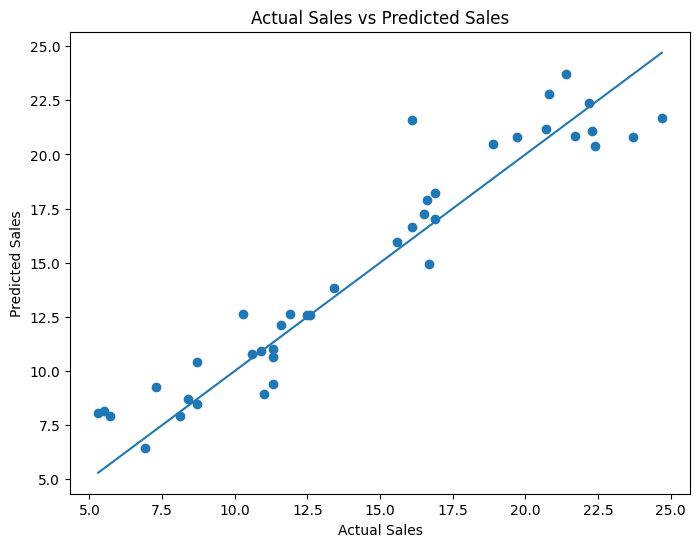

In [15]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual Sales vs Predicted Sales")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.show()

## Interpretation

If the predicted values are close to the diagonal line, the model is performing well.

## 16. Visualize Advertising Coefficients

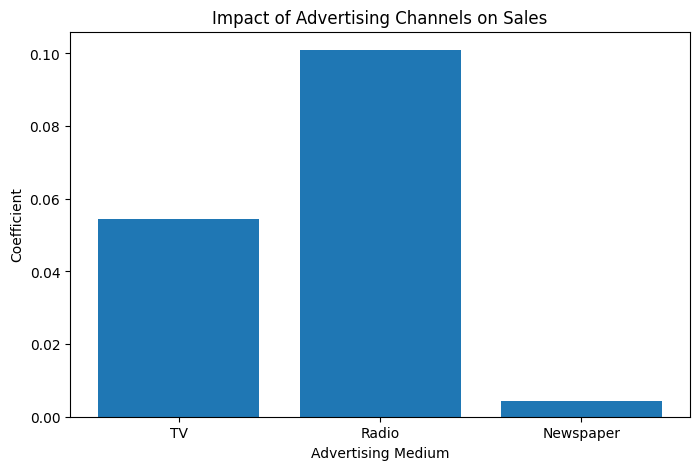

In [16]:
plt.figure(figsize=(8, 5))

plt.bar(X.columns, model.coef_)

plt.xlabel("Advertising Medium")
plt.ylabel("Coefficient")
plt.title("Impact of Advertising Channels on Sales")

plt.show()

## Interpretation

The advertising medium with the highest coefficient has the strongest estimated impact on sales.

## 17. Final Model Summary

In [17]:
print("========== MODEL SUMMARY ==========")

print("\nIntercept:", model.intercept_)

print("\nCoefficients:")
for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

print("\nEvaluation Metrics:")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2  :", r2)

print("\nNew Advertising Budget:")
print("TV = 150")
print("Radio = 20")
print("Newspaper = 30")

print("\nPredicted Sales:", predicted_sales[0])

print("\nStrongest Impact:", strongest)
print("Least Impact:", weakest)

========== MODEL SUMMARY ==========

Intercept: 4.714126402214127

Coefficients:
TV : 0.05450927083721978
Radio : 0.10094536239295579
Newspaper : 0.0043366468220340446

Evaluation Metrics:
MAE : 1.2748262109549338
MSE : 2.9077569102710896
RMSE: 1.7052146229349223
R2  : 0.9059011844150826

New Advertising Budget:
TV = 150
Radio = 20
Newspaper = 30

Predicted Sales: 15.039523680317231

Strongest Impact: Radio
Least Impact: Newspaper


## 18. Business Interpretation
Which advertising medium has the strongest impact?

The medium with the largest regression coefficient has the strongest estimated impact on sales.

Which medium has the least impact?

The medium with the smallest absolute regression coefficient has the least estimated impact.

Business Recommendation

The company should focus more of its advertising budget on the channel that has the strongest positive impact on sales. The company can gradually reduce spending on less effective channels and monitor sales performance.

Technical Improvement

The prediction accuracy can be improved by trying other machine learning models such as:

Random Forest
Gradient Boosting
Ridge Regression
Lasso Regression

Cross-validation and hyperparameter tuning can also be used to select the best-performing model.

## 19. Conclusion

The Multiple Linear Regression model learns the relationship between TV, Radio, Newspaper advertising expenditure and Sales.

The model can:

Analyze advertising data
Predict sales for unseen data
Estimate sales for a new advertising budget
Identify the most influential advertising channel
Measure prediction error using MAE, MSE, RMSE and R²

Overall, the analysis helps the company make better advertising budget decisions based on data.